# 🗂️ MOD-06 — Consolidación del Dataset Maestro

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martín Naranjo Escobar

---

## 📋 Descripción del módulo

Este módulo integra en un único **Dataset Maestro** todas las fuentes procesadas en los módulos anteriores: producción agrícola (MOD-01), temperatura (MOD-03), precipitación y radiación solar (MOD-04) y humedad relativa (MOD-05). La integración se realiza mediante un **LEFT JOIN progresivo** sobre la clave `(Periodo, Departamento, Municipio)`, garantizando que cada fila corresponda a un par municipio-semestre con datos agrícolas y al menos una fuente climática disponible.

La versión **v4.0** aplica un **criterio de cobertura parcial**: Radiación solar obligatoria (NASA POWER, cobertura nacional) + al menos 1 bloque IDEAM, ampliando el universo de ~17–30 municipios (criterio completo v3.0) a **~80–200+ municipios**.

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD06_consolidacion_maestro.ipynb     ← Este archivo
├── data/
│   ├── processed/
│   │   ├── 11_DF_Produccion_Agricola.xlsx    ← Entrada MOD-01
│   │   ├── 12_DF_Municipios_Prioritarios.xlsx← Entrada MOD-01
│   │   ├── 18_DF_Temperatura_Wide.xlsx       ← Entrada MOD-03
│   │   ├── 22_DF_Precipitacion_Wide.xlsx     ← Entrada MOD-04
│   │   ├── 24_DF_Radiacion_Wide.xlsx         ← Entrada MOD-04
│   │   ├── 28_DF_Humedad_Wide.xlsx           ← Entrada MOD-05
│   │   └── 29_DF_Indicadores_Lluvia.xlsx     ← Entrada MOD-05
│   └── master/
│       ├── A1_DF_Consolidado.parquet         ← Salida principal → MOD-07
│       ├── A1_DF_Consolidado.xlsx            ← Inspección visual
│       └── A1_Dashboard.png                  ← Dashboard 9 paneles
└── backup/
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Archivo | Origen |
|------|---------|--------|
| Entrada 1 | `11_DF_Produccion_Agricola.xlsx` | MOD-01 |
| Entrada 2 | `12_DF_Municipios_Prioritarios.xlsx` | MOD-01 |
| Entrada 3 | `18_DF_Temperatura_Wide.xlsx` | MOD-03 |
| Entrada 4 | `22_DF_Precipitacion_Wide.xlsx` | MOD-04 |
| Entrada 5 | `24_DF_Radiacion_Wide.xlsx` | MOD-04 |
| Entrada 6 | `28_DF_Humedad_Wide.xlsx` | MOD-05 |
| Entrada 7 | `29_DF_Indicadores_Lluvia.xlsx` | MOD-05 |
| Salida 1 | `data/master/A1_DF_Consolidado.parquet` | Este módulo |
| Salida 2 | `data/master/A1_DF_Consolidado.xlsx` | Este módulo |
| Salida 3 | `data/master/A1_Dashboard.png` | Este módulo |

---

## 🔗 Dependencias entre módulos

```
MOD-01 → 11_DF_Produccion_Agricola.xlsx
MOD-01 → 12_DF_Municipios_Prioritarios.xlsx
MOD-03 → 18_DF_Temperatura_Wide.xlsx
MOD-04 → 22_DF_Precipitacion_Wide.xlsx
MOD-04 → 24_DF_Radiacion_Wide.xlsx
MOD-05 → 28_DF_Humedad_Wide.xlsx
MOD-05 → 29_DF_Indicadores_Lluvia.xlsx
         └─→ [MOD-06] Dataset Maestro Consolidado
                  └─→ A1_DF_Consolidado.parquet → MOD-07
```

> **Arquitectura v2.0:** Usa `cod_divipola` como llave de join universal. Requiere que **MOD-00** haya sido ejecutado previamente.

---

## 🔄 Flujo de ejecución

| # | Celda | Descripción |
|---|-------|-------------|
| 1 | Entorno | Instalación de dependencias e imports |
| 2 | Rutas y parámetros | Detección automática de `RUTA_BASE`, archivos de entrada/salida y criterios de cobertura parcial v4.0 |
| 3 | Funciones utilitarias | `normalizar_texto()`, `cargar_wide()`, `evaluar_cobertura_minima()` (criterio mixto Obligatorio + Deseable) y `filtrar_municipios_con_periodo_valido()` |
| 4 | Cargar municipios | Universo completo desde hoja `Todos_municipios` (v2.0) con fallback a `Top50_por_cuadrante` |
| 5 | Cargar producción agrícola | Filtra dataset EVA-UPRA a municipios del universo y construye la base del JOIN |
| 6 | Cargar fuentes climáticas | Carga los 5 archivos wide de clima (Temperatura, Precipitación, Radiación, Humedad, Indicadores lluvia) |
| 7 | Diagnóstico pre-JOIN | Evalúa porcentaje de coincidencia entre base agrícola y cada fuente climática |
| 8 | JOIN progresivo | LEFT JOIN secuencial de las 5 fuentes sobre la base agrícola por `(Periodo, Departamento, Municipio)` |
| 9 | Filtro cobertura parcial | Criterio v4.0: Radiación obligatoria + al menos 1 bloque IDEAM. Tabla comparativa v3.0 vs v4.0 |
| 10 | Reorganizar columnas | Ordena por bloques temáticos y optimiza tipos a `float32` |
| 11 | Control de calidad | Verifica duplicados, cobertura por bloque y estadísticas de variables objetivo |
| 12 | Dashboard | Genera `A1_Dashboard.png` con 9 paneles del dataset consolidado |
| 13 | Guardar | Exporta `A1_DF_Consolidado.parquet` (→ MOD-07) y `.xlsx` |
| 14 | Resumen final | Archivos generados, municipios incluidos/excluidos, cobertura temporal y estadísticas |


---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

Instala `openpyxl`, `pyarrow` y librerías necesarias. Importa módulos de pandas, os y gc.

In [1]:
# ============================================================
# MOD-06 — Consolidación Dataset Maestro
# Proyecto: Impacto Variabilidad Climática en Producción Arrocera
# Versión  : 3.0 — Municipios con cobertura climática mínima en al menos 1 periodo
# ============================================================
!pip install openpyxl pyarrow fastparquet -q

import os, gc, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import pyarrow as pa
import pyarrow.parquet as pq
warnings.filterwarnings('ignore')

print('✅ Librerías cargadas')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 13.8 MB/s eta 0:00:00
✅ Librerías cargadas


---
## 📁 CELDA 2 — Configuración de rutas y parámetros

Detecta automáticamente `RUTA_BASE` recorriendo Google Drive. Define rutas de entrada/salida y parámetros del criterio de cobertura parcial v4.0: `BLOQUES_OBLIGATORIOS` (Radiación NASA POWER), `BLOQUES_DESEABLES` (Temperatura, Precipitación, Humedad) y `MIN_BLOQUES_DESEABLES=1`.

In [2]:
# ============================================================
# CONFIGURACION DE RUTAS — MOD-06 v4.0
# ============================================================

from google.colab import drive
import os

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
    print('Google Drive montado')
else:
    print('Google Drive ya estaba montado')

# Deteccion automatica de RUTA_BASE
ARCHIVO_ANCLA = '11_DF_Produccion_Agricola.xlsx'
RUTA_BASE     = None

print()
print('Buscando carpeta del proyecto en Google Drive...')

for dirpath, dirnames, filenames in os.walk('/content/drive/MyDrive'):
    depth = dirpath.replace('/content/drive/MyDrive', '').count(os.sep)
    if depth > 5:
        dirnames.clear()
        continue
    if ARCHIVO_ANCLA in filenames:
        candidate = os.path.dirname(os.path.dirname(dirpath))
        if os.path.isdir(os.path.join(candidate, 'data', 'processed')):
            RUTA_BASE = candidate
            print(f'   Proyecto encontrado en: {RUTA_BASE}')
            break

if RUTA_BASE is None:
    RUTA_BASE = '/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II'
    print(f'   No encontrado automaticamente. Usando: {RUTA_BASE}')

RUTA_PROCESSED = os.path.join(RUTA_BASE, 'data', 'processed')
RUTA_MASTER    = os.path.join(RUTA_BASE, 'data', 'master')
RUTA_BACKUP    = os.path.join(RUTA_BASE, 'backup')

for ruta in [RUTA_MASTER, RUTA_BACKUP]:
    os.makedirs(ruta, exist_ok=True)

# Archivos de ENTRADA
ENTRADA_PRODUCCION  = os.path.join(RUTA_PROCESSED, '11_DF_Produccion_Agricola.xlsx')
ENTRADA_MUNICIPIOS  = os.path.join(RUTA_PROCESSED, '12_DF_Municipios_Prioritarios.xlsx')
ENTRADA_TEMP_WIDE   = os.path.join(RUTA_PROCESSED, '18_DF_Temperatura_Wide.xlsx')
ENTRADA_PREC_WIDE   = os.path.join(RUTA_PROCESSED, '22_DF_Precipitacion_Wide.xlsx')
ENTRADA_RAD_WIDE    = os.path.join(RUTA_PROCESSED, '24_DF_Radiacion_Wide.xlsx')
ENTRADA_HR_WIDE     = os.path.join(RUTA_PROCESSED, '28_DF_Humedad_Wide.xlsx')
ENTRADA_LLUVIA_WIDE = os.path.join(RUTA_PROCESSED, '29_DF_Indicadores_Lluvia.xlsx')

# Archivos de SALIDA
ARCHIVO_CONSOLIDADO         = os.path.join(RUTA_MASTER, 'A1_DF_Consolidado.xlsx')
ARCHIVO_CONSOLIDADO_PARQUET = os.path.join(RUTA_MASTER, 'A1_DF_Consolidado.parquet')

# Clave de join
COLS_JOIN = ['Periodo', 'Departamento', 'Municipio']

# ── Hoja de municipios: v2.0 usa Todos_municipios (universo completo) ──
# Si la hoja no existe, hace fallback a Top50_por_cuadrante (compatibilidad v1.0)
HOJA_MUNICIPIOS_V2 = 'Todos_municipios'
HOJA_MUNICIPIOS_V1 = 'Top50_por_cuadrante'

# ── Parametros de cobertura parcial v4.0 ──────────────────────────────
# Bloque OBLIGATORIO: Radiacion (NASA POWER cubre 100% del territorio)
BLOQUES_OBLIGATORIOS = {
    'Radiacion': 'radiacion_',
}

# Bloques DESEABLES: al menos MIN_BLOQUES_DESEABLES de estos 3
BLOQUES_DESEABLES = {
    'Temperatura'  : 'temperatura_',
    'Precipitacion': 'precipitacion_',
    'Humedad'      : 'hr_',
}
MIN_BLOQUES_DESEABLES = 1   # al menos 1 de los 3 bloques IDEAM

APLICAR_FILTRO_COBERTURA = True

print()
print('Rutas configuradas:')
print(f'   Base      -> {RUTA_BASE}')
print(f'   Processed -> {RUTA_PROCESSED}')
print(f'   Master    -> {RUTA_MASTER}')
print()
print('Criterio de cobertura v4.0:')
print(f'   Bloque OBLIGATORIO : {list(BLOQUES_OBLIGATORIOS.keys())} (NASA POWER)')
print(f'   Bloques DESEABLES  : {list(BLOQUES_DESEABLES.keys())} (IDEAM)')
print(f'   Minimo deseables   : {MIN_BLOQUES_DESEABLES} de {len(BLOQUES_DESEABLES)}')
print(f'   Regla resumida     : Radiacion + al menos 1 bloque IDEAM')
print()
print('Verificando archivos de entrada:')

entradas = [
    ('11_DF_Produccion_Agricola.xlsx',     ENTRADA_PRODUCCION),
    ('12_DF_Municipios_Prioritarios.xlsx', ENTRADA_MUNICIPIOS),
    ('18_DF_Temperatura_Wide.xlsx',        ENTRADA_TEMP_WIDE),
    ('22_DF_Precipitacion_Wide.xlsx',      ENTRADA_PREC_WIDE),
    ('24_DF_Radiacion_Wide.xlsx',          ENTRADA_RAD_WIDE),
    ('28_DF_Humedad_Wide.xlsx',            ENTRADA_HR_WIDE),
    ('29_DF_Indicadores_Lluvia.xlsx',      ENTRADA_LLUVIA_WIDE),
]

todas_ok = True
for nombre, ruta in entradas:
    existe = os.path.exists(ruta)
    if not existe:
        todas_ok = False
    print(f'   {"OK" if existe else "FALTANTE"}  {nombre}')

if not todas_ok:
    raise FileNotFoundError('Faltan archivos de entrada. Ejecuta MOD-01 a MOD-05 primero.')

print()
print('Todos los archivos encontrados.')


Mounted at /content/drive
Google Drive montado

Buscando carpeta del proyecto en Google Drive...
   Proyecto encontrado en: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II

Rutas configuradas:
   Base      -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II
   Processed -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed
   Master    -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master

Criterio de cobertura v4.0:
   Bloque OBLIGATORIO : ['Radiacion'] (NASA POWER)
   Bloques DESEABLES  : ['Temperatura', 'Precipitacion', 'Humedad'] (IDEAM)
   Minimo deseables   : 1 de 3
   Regla resumida     : Radiacion + al menos 1 bloque IDEAM

Verificando archivos de entrada:
   OK  11_DF_Produccion_Agricola.xlsx
   OK  12_DF_Municipios_Prioritarios.xlsx
   OK  18_DF_Temperatura_Wide.xlsx
   OK  22_DF_Precipitacion_Wide.xlsx
   OK  24_DF_Radiacion_Wide.xlsx
   OK  28_DF_Humedad_Wide.xlsx
   OK  29_DF_Indicadores_Lluvia.xlsx

Todos

---
## 🔧 CELDA 3 — Funciones utilitarias

Define `normalizar_texto()` (mayúsculas + strip), `cargar_wide()` (carga archivos formato wide), `reporte_df()` (diagnóstico de nulos), `guardar_maestro()` (Parquet + Excel), `evaluar_cobertura_minima()` (criterio mixto Obligatorio AND Deseable) y `filtrar_municipios_con_periodo_valido()`.

In [3]:
# ============================================================
# FUNCIONES UTILITARIAS — MOD-06 v4.0
# Incluye evaluar_cobertura_minima con criterio MIXTO:
#   - Bloques OBLIGATORIOS: deben tener dato en TODOS
#   - Bloques DESEABLES   : deben cumplir al menos MIN
# ============================================================

def normalizar_texto(serie):
    return serie.astype(str).str.strip().str.upper()


def cargar_wide(ruta, nombre_log, hoja=0):
    df = pd.read_excel(ruta, sheet_name=hoja, engine='openpyxl')
    rename = {}
    for col in df.columns:
        col_l = col.lower().strip()
        if col_l == 'departamento': rename[col] = 'Departamento'
        elif col_l == 'municipio':  rename[col] = 'Municipio'
        elif col_l == 'periodo':    rename[col] = 'Periodo'
    if rename:
        df = df.rename(columns=rename)
    for col_id in ['Departamento', 'Municipio', 'Periodo']:
        if col_id in df.columns:
            df[col_id] = normalizar_texto(df[col_id])
    n_feat = len([c for c in df.columns if c not in ['Periodo','Departamento','Municipio']])
    print(f'   OK {nombre_log}: {df.shape[0]:,} filas x {df.shape[1]} cols ({n_feat} features)')
    return df


def reporte_df(df, nombre=''):
    sep = '=' * 62
    print(f'\n{sep}\n  DataFrame — {nombre}\n{sep}')
    print(f'  Filas    : {df.shape[0]:,}')
    print(f'  Columnas : {df.shape[1]}')
    nulos = df.isna().sum()
    nulos_c = nulos[nulos > 0]
    if nulos_c.empty:
        print('  Nulos    : Sin valores nulos')
    else:
        print(f'  Nulos    : {len(nulos_c)} cols con nulos')
        for c, n in nulos_c.items():
            print(f'             - {c}: {n:,} ({n/len(df)*100:.1f}%)')
    print(f'{sep}\n')


def guardar_maestro(df, ruta_xlsx, ruta_parquet):
    MAX_EXCEL = 1_048_576
    df.to_parquet(ruta_parquet, index=False, engine='pyarrow', compression='snappy')
    print(f'   OK Parquet -> {ruta_parquet}')
    print(f'      {df.shape[0]:,} filas x {df.shape[1]} cols')
    if df.shape[0] <= MAX_EXCEL:
        df.to_excel(ruta_xlsx, index=False, engine='openpyxl')
        print(f'   OK Excel  -> {ruta_xlsx}')
    else:
        df.head(MAX_EXCEL).to_excel(ruta_xlsx, index=False, engine='openpyxl')
        print(f'   AVISO Excel: truncado a {MAX_EXCEL:,} filas (total: {df.shape[0]:,}). Usar Parquet para MOD-07.')


def evaluar_cobertura_minima(df,
                              bloques_obligatorios,
                              bloques_deseables=None,
                              min_bloques_deseables=1):
    '''
    Criterio MIXTO de cobertura v4.0:

    - Bloques OBLIGATORIOS: el municipio-periodo debe tener al menos
      1 valor no-nulo en CADA uno de estos bloques (todos obligatorios).
      Ejemplo: Radiacion (NASA POWER tiene cobertura nacional).

    - Bloques DESEABLES: el municipio-periodo debe tener al menos
      min_bloques_deseables de estos bloques con al menos 1 valor no-nulo.
      Ejemplo: al menos 1 de (Temperatura, Precipitacion, Humedad).

    Una fila recibe cobertura_ok=True si cumple AMBAS condiciones.

    Retorna:
        df_flags : DataFrame con columnas booleanas por bloque y cobertura_ok
        resumen  : dict con estadisticas del filtro
    '''
    df_flags = pd.DataFrame(index=df.index)

    # ── Evaluar bloques OBLIGATORIOS ─────────────────────────
    for nombre, prefijo in bloques_obligatorios.items():
        cols = [c for c in df.columns if c.startswith(prefijo)]
        df_flags['oblig_' + nombre.lower()] = (
            df[cols].notna().any(axis=1) if cols
            else pd.Series(False, index=df.index)
        )

    cols_oblig = [c for c in df_flags.columns if c.startswith('oblig_')]
    todos_oblig = (
        df_flags[cols_oblig].all(axis=1)
        if cols_oblig
        else pd.Series(True, index=df.index)
    )

    # ── Evaluar bloques DESEABLES ─────────────────────────────
    if bloques_deseables:
        for nombre, prefijo in bloques_deseables.items():
            cols = [c for c in df.columns if c.startswith(prefijo)]
            df_flags['deseable_' + nombre.lower()] = (
                df[cols].notna().any(axis=1) if cols
                else pd.Series(False, index=df.index)
            )
        cols_deseable = [c for c in df_flags.columns if c.startswith('deseable_')]
        n_deseables_ok = df_flags[cols_deseable].sum(axis=1)
        cumple_deseables = n_deseables_ok >= min_bloques_deseables
    else:
        cumple_deseables = pd.Series(True, index=df.index)

    # ── Cobertura final: obligatorios AND deseables ───────────
    df_flags['cobertura_ok'] = todos_oblig & cumple_deseables

    resumen = {
        'total_filas'    : len(df),
        'filas_ok'       : int(df_flags['cobertura_ok'].sum()),
        'filas_excluidas': int((~df_flags['cobertura_ok']).sum()),
        'por_bloque': {
            col: int(df_flags[col].sum())
            for col in df_flags.columns if col != 'cobertura_ok'
        }
    }
    return df_flags, resumen


def filtrar_municipios_con_periodo_valido(df, df_flags):
    '''
    Regla: un municipio se incluye en el maestro SOLO si tiene
    AL MENOS 1 periodo con cobertura_ok=True.
    Se conservan unicamente las filas (periodos) con cobertura_ok=True
    de esos municipios.
    '''
    df_con_flag = df.copy()
    df_con_flag['_cob_ok'] = df_flags['cobertura_ok'].values

    munis_validos_df = (
        df_con_flag.groupby(['Departamento', 'Municipio'])['_cob_ok']
        .any().reset_index()
    )
    munis_validos = set(
        zip(
            munis_validos_df[munis_validos_df['_cob_ok']]['Departamento'],
            munis_validos_df[munis_validos_df['_cob_ok']]['Municipio']
        )
    )
    munis_excluidos = set(zip(df['Departamento'], df['Municipio'])) - munis_validos

    mask_final = (
        df_con_flag['_cob_ok'] &
        df_con_flag.apply(
            lambda r: (r['Departamento'], r['Municipio']) in munis_validos, axis=1
        )
    )
    df_filtrado = df[mask_final].copy()

    reporte = {
        'munis_originales' : df[['Departamento','Municipio']].drop_duplicates().shape[0],
        'munis_validos'    : len(munis_validos),
        'munis_excluidos'  : len(munis_excluidos),
        'lista_excluidos'  : sorted(munis_excluidos),
        'periodos_validos' : int(mask_final.sum()),
    }
    return df_filtrado.reset_index(drop=True), reporte


print('OK Funciones utilitarias cargadas (criterio cobertura v4.0)')


OK Funciones utilitarias cargadas (criterio cobertura v4.0)


---
## 🏘️ CELDA 4 — Cargar universo de municipios arroceros

Lee `12_DF_Municipios_Prioritarios.xlsx` priorizando la hoja `Todos_municipios` (universo completo v2.0). Si no existe, usa fallback `Top50_por_cuadrante`. Construye `pares_prioritarios` (set de tuplas Departamento-Municipio) para filtro O(1).

In [4]:
# ============================================================
# CARGAR MUNICIPIOS — 12_DF_Municipios_Prioritarios.xlsx
# v4.0: usa hoja 'Todos_municipios' (universo completo MOD-01 v2.0)
# Fallback a 'Top50_por_cuadrante' si la hoja no existe.
# ============================================================

import pandas as pd

# Detectar hoja disponible
xls_munis = pd.ExcelFile(ENTRADA_MUNICIPIOS, engine='openpyxl')
hojas_disponibles = xls_munis.sheet_names
print('Hojas disponibles en 12_DF_Municipios_Prioritarios.xlsx:')
for h in hojas_disponibles:
    print(f'   - {h}')
print()

if HOJA_MUNICIPIOS_V2 in hojas_disponibles:
    hoja_usar = HOJA_MUNICIPIOS_V2
    print(f'Usando hoja v2.0: {hoja_usar} (universo completo)')
else:
    hoja_usar = HOJA_MUNICIPIOS_V1
    print(f'AVISO: hoja Todos_municipios no encontrada.')
    print(f'Usando fallback: {hoja_usar}')
    print('Para usar el universo completo, re-ejecuta MOD-01 v2.0')

print()
print(f'Cargando municipios desde hoja: {hoja_usar}')
df_top50 = pd.read_excel(ENTRADA_MUNICIPIOS, sheet_name=hoja_usar, engine='openpyxl')

df_top50['Departamento'] = normalizar_texto(df_top50['Departamento'])
df_top50['Municipio']    = normalizar_texto(df_top50['Municipio'])

# Conjunto de pares para filtro O(1)
pares_prioritarios = set(zip(df_top50['Departamento'], df_top50['Municipio']))

print(f'   Total municipios en el universo: {len(pares_prioritarios)}')

if 'Cuadrante' in df_top50.columns:
    print('   Distribucion por cuadrante:')
    for q, n in df_top50['Cuadrante'].value_counts().sort_index().items():
        print(f'     {q}: {n} municipios')
else:
    print('   (columna Cuadrante no disponible en esta hoja)')

print()
print('   Lista de municipios (primeros 20):')
for depto, mpio in sorted(list(pares_prioritarios))[:20]:
    print(f'     {depto} -- {mpio}')
if len(pares_prioritarios) > 20:
    print(f'     ... y {len(pares_prioritarios)-20} mas')


Hojas disponibles en 12_DF_Municipios_Prioritarios.xlsx:
   - Todos_municipios
   - Top50_por_cuadrante
   - Resumen_departamento

Usando hoja v2.0: Todos_municipios (universo completo)

Cargando municipios desde hoja: Todos_municipios
   Total municipios en el universo: 131
   Distribucion por cuadrante:
     Q1 - Alto Rend + Alta Prod: 37 municipios
     Q2 - Alto Rend + Baja Prod: 29 municipios
     Q3 - Bajo Rend + Alta Prod: 29 municipios
     Q4 - Bajo Rend + Baja Prod: 36 municipios

   Lista de municipios (primeros 20):
     ANTIOQUIA -- PUERTO BERRÍO
     ARAUCA -- FORTUL
     ATLÁNTICO -- PONEDERA
     ATLÁNTICO -- REPELÓN
     ATLÁNTICO -- SUAN
     BOLÍVAR -- ACHÍ
     BOLÍVAR -- ARENAL
     BOLÍVAR -- CLEMENCIA
     BOLÍVAR -- CÓRDOBA
     BOLÍVAR -- MAHATES
     BOLÍVAR -- MARÍA LA BAJA
     BOLÍVAR -- MORALES
     BOLÍVAR -- REGIDOR
     CASANARE -- AGUAZUL
     CASANARE -- NUNCHÍA
     CASANARE -- PAZ DE ARIPORO
     CASANARE -- PORE
     CASANARE -- SAN LUIS DE PALENQU

---
## 🌾 CELDA 5 — Cargar y filtrar producción agrícola

Carga `11_DF_Produccion_Agricola.xlsx`, normaliza columnas ID, filtra a los municipios prioritarios y reporta la distribución por cuadrante. Este DataFrame es la base (lado izquierdo) del JOIN progresivo.

In [5]:
# ============================================================
# CARGAR Y FILTRAR PRODUCCIÓN AGRÍCOLA — 11_DF_Produccion_Agricola.xlsx
# Solo se retienen filas de municipios prioritarios
# ============================================================

print('📥 Cargando producción agrícola (MOD-01)...')
df_produccion_full = pd.read_excel(ENTRADA_PRODUCCION, engine='openpyxl')

df_produccion_full['Departamento'] = normalizar_texto(df_produccion_full['Departamento'])
df_produccion_full['Municipio']    = normalizar_texto(df_produccion_full['Municipio'])

# Asegurar columna Periodo
if 'Periodo' not in df_produccion_full.columns:
    if 'Año' in df_produccion_full.columns and 'Semestre' in df_produccion_full.columns:
        df_produccion_full['Periodo'] = (
            df_produccion_full['Año'].astype(str)
            + df_produccion_full['Semestre'].astype(str).str.strip().str.upper()
        )
        print('   Columna Periodo reconstruida desde Año + Semestre')
df_produccion_full['Periodo'] = (
    df_produccion_full['Periodo'].astype(str).str.strip().str.upper()
)

n_total = len(df_produccion_full)
print(f'   Shape original : {n_total:,} filas × {df_produccion_full.shape[1]} cols')
print(f'   Municipios únicos (total EVA): '
      f'{df_produccion_full[["Departamento","Municipio"]].drop_duplicates().shape[0]}')

# ── FILTRO PRINCIPAL: Solo municipios prioritarios ────────────
print()
print('🔎 Filtrando a municipios prioritarios...')
mask_prio = df_produccion_full.apply(
    lambda r: (r['Departamento'], r['Municipio']) in pares_prioritarios, axis=1
)
df_produccion = df_produccion_full[mask_prio].copy().reset_index(drop=True)
del df_produccion_full
gc.collect()

n_filtrado = len(df_produccion)
n_excluido = n_total - n_filtrado
pct_ret    = n_filtrado / n_total * 100 if n_total else 0

print(f'   Filas retenidas  : {n_filtrado:,} ({pct_ret:.1f}%)')
print(f'   Filas excluidas  : {n_excluido:,} ({100 - pct_ret:.1f}%) — no prioritarios')
print(f'   Municipios retenidos: '
      f'{df_produccion[["Departamento","Municipio"]].drop_duplicates().shape[0]}')

# Añadir columna Cuadrante desde df_top50
df_produccion = df_produccion.merge(
    df_top50[['Departamento', 'Municipio', 'Cuadrante']].drop_duplicates(),
    on=['Departamento', 'Municipio'],
    how='left'
)

COL_PRODUCCION  = 'Producción (t)'
COL_RENDIMIENTO = 'Rendimiento (t/ha)'
COL_AREA        = 'Área (ha)' if 'Área (ha)' in df_produccion.columns else None

print()
print(f'   Periodos : {sorted(df_produccion["Periodo"].unique())}')
print(f'   Columnas : {df_produccion.columns.tolist()}')
print()
display(df_produccion.head(4))

📥 Cargando producción agrícola (MOD-01)...
   Shape original : 1,162 filas × 17 cols
   Municipios únicos (total EVA): 131

🔎 Filtrando a municipios prioritarios...
   Filas retenidas  : 1,162 (100.0%)
   Filas excluidas  : 0 (0.0%) — no prioritarios
   Municipios retenidos: 131

   Periodos : ['2020A', '2020B', '2021A', '2021B', '2022A', '2022B', '2023A', '2023B', '2024A', '2024B']
   Columnas : ['Código Dane departamento', 'Departamento', 'Código Dane municipio', 'Municipio', 'Desagregación cultivo', 'Cultivo', 'Ciclo del cultivo', 'Grupo cultivo', 'Subgrupo', 'Año', 'Periodo', 'Área sembrada (ha)', 'Área cosechada (ha)', 'Producción (t)', 'Rendimiento (t/ha)', 'Nombre científico del cultivo', 'Estado físico del cultivo', 'Cuadrante']



,Código Dane departamento,Departamento,Código Dane municipio,Municipio,Desagregación cultivo,Cultivo,Ciclo del cultivo,Grupo cultivo,Subgrupo,Año,Periodo,Área sembrada (ha),Área cosechada (ha),Producción (t),Rendimiento (t/ha),Nombre científico del cultivo,Estado físico del cultivo,Cuadrante
0,5,ANTIOQUIA,5579,PUERTO BERRÍO,ARROZ RIEGO,ARROZ,TRANSITORIO,CEREALES,CEREALES,2020,2020A,110.0,110.0,654.5,5.95,ORYZA SATIVA,PADDY O CÁSCARA VERDE,Q4 - Bajo Rend + Baja Prod
1,5,ANTIOQUIA,5579,PUERTO BERRÍO,ARROZ RIEGO,ARROZ,TRANSITORIO,CEREALES,CEREALES,2021,2021A,110.0,110.0,550.0,5.00,ORYZA SATIVA,PADDY O CÁSCARA VERDE,Q4 - Bajo Rend + Baja Prod
2,5,ANTIOQUIA,5579,PUERTO BERRÍO,ARROZ RIEGO,ARROZ,TRANSITORIO,CEREALES,CEREALES,2022,2022A,100.0,100.0,500.0,5.00,ORYZA SATIVA,PADDY O CÁSCARA VERDE,Q4 - Bajo Rend + Baja Prod
3,5,ANTIOQUIA,5579,PUERTO BERRÍO,ARROZ RIEGO,ARROZ,TRANSITORIO,CEREALES,CEREALES,2022,2022B,110.0,110.0,550.0,5.00,ORYZA SATIVA,PADDY O CÁSCARA VERDE,Q4 - Bajo Rend + Baja Prod


---
## 🌡️ CELDA 6 — Cargar fuentes climáticas en formato wide

Carga los 5 archivos wide generados por MOD-03 a MOD-05. Cada archivo contiene columnas `m1..m6` por variable climática. Normaliza nombres de columnas ID y reporta el número de features por bloque.

In [6]:
# ============================================================
# CARGAR FUENTES CLIMÁTICAS — Formato wide (m1..m6)
# ============================================================

print('📥 Cargando archivos wide de clima...')
print()

df_temp_wide   = cargar_wide(ENTRADA_TEMP_WIDE,   '18_DF_Temperatura_Wide.xlsx')
df_prec_wide   = cargar_wide(ENTRADA_PREC_WIDE,   '22_DF_Precipitacion_Wide.xlsx')
df_rad_wide    = cargar_wide(ENTRADA_RAD_WIDE,    '24_DF_Radiacion_Wide.xlsx')
df_hr_wide     = cargar_wide(ENTRADA_HR_WIDE,     '28_DF_Humedad_Wide.xlsx')
df_lluvia_wide = cargar_wide(
    ENTRADA_LLUVIA_WIDE,
    '29_DF_Indicadores_Lluvia.xlsx (hoja: Indicadores_Wide)',
    hoja='Indicadores_Wide'
)

print()
print('📋 Features climáticas por bloque:')
cols_id = ['Periodo', 'Departamento', 'Municipio']
for nombre_b, df_b in [
    ('Temperatura',   df_temp_wide),
    ('Precipitacion', df_prec_wide),
    ('Radiacion',     df_rad_wide),
    ('Humedad HR',    df_hr_wide),
    ('Ind. lluvia',   df_lluvia_wide),
]:
    feat = [c for c in df_b.columns if c not in cols_id]
    print(f'   {nombre_b:15s}: {len(feat):3d} features')

📥 Cargando archivos wide de clima...

   OK 18_DF_Temperatura_Wide.xlsx: 254 filas x 27 cols (24 features)
   OK 22_DF_Precipitacion_Wide.xlsx: 394 filas x 33 cols (30 features)
   OK 24_DF_Radiacion_Wide.xlsx: 1,050 filas x 15 cols (12 features)
   OK 28_DF_Humedad_Wide.xlsx: 253 filas x 45 cols (42 features)
   OK 29_DF_Indicadores_Lluvia.xlsx (hoja: Indicadores_Wide): 3 filas x 21 cols (18 features)

📋 Features climáticas por bloque:
   Temperatura    :  24 features
   Precipitacion  :  30 features
   Radiacion      :  12 features
   Humedad HR     :  42 features
   Ind. lluvia    :  18 features


---
## 🔍 CELDA 7 — Diagnóstico de cobertura pre-JOIN

Antes del JOIN, evalúa qué porcentaje de pares (Periodo, Departamento, Municipio) de la base agrícola tienen datos en cada fuente climática. Identifica brechas territoriales que serán imputadas en MOD-07.

In [7]:
# ============================================================
# DIAGNÓSTICO DE COBERTURA PRE-JOIN
# Universo: municipios prioritarios Top-50 por cuadrante
# ============================================================

sep = '=' * 65
print(sep)
print('  DIAGNÓSTICO DE COBERTURA PRE-JOIN')
print('  (Universo: municipios prioritarios)')
print(sep)

df_produccion['_key3'] = (
    df_produccion['Periodo'] + '|'
    + df_produccion['Departamento'] + '|'
    + df_produccion['Municipio']
)
keys_prod = set(df_produccion['_key3'].unique())
n_prod    = len(keys_prod)

print(f'\n  Base EVA (municipios prioritarios):')
print(f'  Filas totales  : {len(df_produccion):,}')
print(f'  Claves únicas  : {n_prod:,}  (Periodo|Depto|Municipio)')
print(f'  Periodos       : {sorted(df_produccion["Periodo"].unique())}')
print()

fuentes = [
    ('Temperatura    (MOD-03)', df_temp_wide),
    ('Precipitación  (MOD-04)', df_prec_wide),
    ('Radiación      (MOD-04)', df_rad_wide),
    ('Humedad rel.   (MOD-05)', df_hr_wide),
    ('Ind. lluvia    (MOD-05)', df_lluvia_wide),
]

resumen = []
for nombre_f, df_f in fuentes:
    df_f['_key3'] = (
        df_f['Periodo'] + '|'
        + df_f['Departamento'] + '|'
        + df_f['Municipio']
    )
    keys_f  = set(df_f['_key3'].unique())
    n_match = len(keys_prod & keys_f)
    n_gap   = len(keys_prod - keys_f)
    n_extra = len(keys_f - keys_prod)
    pct     = n_match / n_prod * 100 if n_prod else 0
    emoji   = '✅' if pct >= 70 else ('⚠️ ' if pct >= 40 else '❌')
    print(f'  {emoji} {nombre_f}')
    print(f'       Match EVA↔clima  : {n_match:,} / {n_prod:,}  ({pct:.1f}%)')
    print(f'       Gap (EVA s/dato) : {n_gap:,}  → imputar en MOD-07')
    print(f'       Extra (clima+)   : {n_extra:,}  → no incorporados')
    print()
    resumen.append({'Fuente': nombre_f.strip(), 'Match': n_match,
                    'Total_EVA': n_prod, 'Cobertura_pct': round(pct, 1),
                    'Gap_EVA': n_gap})

df_cobertura_pre = pd.DataFrame(resumen)
print('📊 Tabla resumen cobertura pre-join:')
display(df_cobertura_pre)

df_produccion.drop(columns=['_key3'], inplace=True)
for _, df_f in fuentes:
    if '_key3' in df_f.columns:
        df_f.drop(columns=['_key3'], inplace=True)

  DIAGNÓSTICO DE COBERTURA PRE-JOIN
  (Universo: municipios prioritarios)

  Base EVA (municipios prioritarios):
  Filas totales  : 1,162
  Claves únicas  : 1,162  (Periodo|Depto|Municipio)
  Periodos       : ['2020A', '2020B', '2021A', '2021B', '2022A', '2022B', '2023A', '2023B', '2024A', '2024B']

  ❌ Temperatura    (MOD-03)
       Match EVA↔clima  : 234 / 1,162  (20.1%)
       Gap (EVA s/dato) : 928  → imputar en MOD-07
       Extra (clima+)   : 20  → no incorporados

  ❌ Precipitación  (MOD-04)
       Match EVA↔clima  : 361 / 1,162  (31.1%)
       Gap (EVA s/dato) : 801  → imputar en MOD-07
       Extra (clima+)   : 33  → no incorporados

  ✅ Radiación      (MOD-04)
       Match EVA↔clima  : 961 / 1,162  (82.7%)
       Gap (EVA s/dato) : 201  → imputar en MOD-07
       Extra (clima+)   : 89  → no incorporados

  ❌ Humedad rel.   (MOD-05)
       Match EVA↔clima  : 233 / 1,162  (20.1%)
       Gap (EVA s/dato) : 929  → imputar en MOD-07
       Extra (clima+)   : 20  → no incorporados


,Fuente,Match,Total_EVA,Cobertura_pct,Gap_EVA
0,Temperatura (MOD-03),234,1162,20.1,928
1,Precipitación (MOD-04),361,1162,31.1,801
2,Radiación (MOD-04),961,1162,82.7,201
3,Humedad rel. (MOD-05),233,1162,20.1,929
4,Ind. lluvia (MOD-05),2,1162,0.2,1160


---
## 🔗 CELDA 8 — JOIN progresivo LEFT JOIN

Une secuencialmente las 5 fuentes climáticas a la base agrícola mediante LEFT JOIN sobre `(Periodo, Departamento, Municipio)`. Verifica que el número de filas no cambia tras el JOIN. Libera memoria con `gc.collect()` después de cada fuente.

In [8]:
# ============================================================
# JOIN PROGRESIVO — LEFT JOIN sobre (Periodo, Departamento, Municipio)
# ============================================================

sep = '=' * 65
print(sep)
print('  JOIN PROGRESIVO — Consolidación')
print(f'  Clave    : {COLS_JOIN}  (normalizadas a MAYÚSCULAS)')
print(f'  Universo : {len(pares_prioritarios)} municipios prioritarios')
print(sep)
print()

def left_join_clima(df_base, df_clima, nombre_fuente):
    cols_id   = ['Periodo', 'Departamento', 'Municipio']
    cols_feat = [c for c in df_clima.columns if c not in cols_id]
    cols_base_set = set(df_base.columns)
    rename_map = {}
    for c in cols_feat:
        if c in cols_base_set:
            tag = nombre_fuente.split()[0].lower()
            rename_map[c] = f'{c}_{tag}'
    if rename_map:
        df_clima = df_clima.rename(columns=rename_map)
        cols_feat = [rename_map.get(c, c) for c in cols_feat]
        print(f'   ⚠️  {nombre_fuente}: renombradas {list(rename_map.keys())}')
    df_merged = df_base.merge(
        df_clima[cols_id + cols_feat], on=cols_id, how='left'
    )
    if cols_feat:
        n_con = df_merged[cols_feat[0]].notna().sum()
        pct   = n_con / len(df_merged) * 100
        emoji = '✅' if pct >= 70 else ('⚠️ ' if pct >= 40 else '❌')
        print(f'   {emoji} {nombre_fuente}: {n_con:,}/{len(df_merged):,} '
              f'({pct:.1f}%) | +{len(cols_feat)} cols')
    del df_clima
    gc.collect()
    return df_merged


df_maestro = df_produccion.copy()
n_base = len(df_maestro)
print(f'   Base EVA (prioritarios): {n_base:,} filas × {df_maestro.shape[1]} cols')
print()

df_maestro = left_join_clima(df_maestro, df_temp_wide,   'Temperatura   (MOD-03)')
df_maestro = left_join_clima(df_maestro, df_prec_wide,   'Precipitación (MOD-04)')
df_maestro = left_join_clima(df_maestro, df_rad_wide,    'Radiación     (MOD-04)')
df_maestro = left_join_clima(df_maestro, df_hr_wide,     'Humedad rel.  (MOD-05)')
df_maestro = left_join_clima(df_maestro, df_lluvia_wide, 'Ind. lluvia   (MOD-05)')

print()
assert len(df_maestro) == n_base, (
    f'El JOIN modificó el número de filas: {n_base} → {len(df_maestro)}'
)
print(f'✅ JOIN completado: {len(df_maestro):,} filas × {df_maestro.shape[1]} cols')
print(f'   Integridad verificada: filas base = filas resultado = {n_base:,}')

  JOIN PROGRESIVO — Consolidación
  Clave    : ['Periodo', 'Departamento', 'Municipio']  (normalizadas a MAYÚSCULAS)
  Universo : 131 municipios prioritarios

   Base EVA (prioritarios): 1,162 filas × 18 cols

   ❌ Temperatura   (MOD-03): 175/1,162 (15.1%) | +24 cols
   ❌ Precipitación (MOD-04): 283/1,162 (24.4%) | +30 cols
   ✅ Radiación     (MOD-04): 961/1,162 (82.7%) | +12 cols
   ❌ Humedad rel.  (MOD-05): 174/1,162 (15.0%) | +42 cols
   ❌ Ind. lluvia   (MOD-05): 2/1,162 (0.2%) | +18 cols

✅ JOIN completado: 1,162 filas × 144 cols
   Integridad verificada: filas base = filas resultado = 1,162


---
## 🔎 CELDA 9 — Filtro de cobertura parcial v4.0

Aplica criterio mixto: Radiación obligatoria (NASA POWER) + al menos 1 bloque IDEAM. Muestra tabla detallada de municipios incluidos con sus periodos válidos, municipios excluidos y comparativa cuantitativa v3.0 vs v4.0 con números reales de la ejecución.

In [9]:
# ============================================================
# FILTRO DE COBERTURA PARCIAL — v4.0
#
# Criterio de inclusion (2 dimensiones minimas):
#   OBLIGATORIO : Radiacion (NASA POWER — cobertura nacional)
#   DESEABLE    : al menos 1 de (Temperatura, Precipitacion, Humedad)
#
# Un municipio se incluye si tiene AL MENOS 1 periodo que
# cumpla ambas condiciones. Los demas periodos de ese municipio
# se descartan (no se imputan en este modulo).
#
# Diferencia con v3.0:
#   v3.0: exigia los 4 bloques -> ~17-30 municipios
#   v4.0: exige 2 dimensiones  -> ~80-200+ municipios
# ============================================================

sep = '=' * 65
print(sep)
print('  FILTRO DE COBERTURA PARCIAL v4.0')
print(f'  Bloque OBLIGATORIO : {list(BLOQUES_OBLIGATORIOS.keys())} (NASA POWER)')
print(f'  Bloques DESEABLES  : {list(BLOQUES_DESEABLES.keys())}')
print(f'  Minimo deseables   : {MIN_BLOQUES_DESEABLES} de {len(BLOQUES_DESEABLES)}')
print(sep)
print()

# ── Paso 1: Evaluar cobertura por fila ───────────────────────
df_flags, resumen_cob = evaluar_cobertura_minima(
    df_maestro,
    bloques_obligatorios  = BLOQUES_OBLIGATORIOS,
    bloques_deseables     = BLOQUES_DESEABLES,
    min_bloques_deseables = MIN_BLOQUES_DESEABLES
)

n_total = resumen_cob['total_filas']

print('Cobertura por bloque:')
print(f'  {"Bloque":<30}  {"Filas con dato":>15}  {"Pct":>8}  Tipo')
print(f'  {"-"*60}')

for col, n_con in resumen_cob['por_bloque'].items():
    pct = n_con / n_total * 100 if n_total else 0
    if col.startswith('oblig_'):
        tipo  = 'OBLIGATORIO'
        emoji = 'OK' if pct >= 50 else 'AVISO'
        label = col.replace('oblig_', '')
    else:
        tipo  = 'deseable'
        emoji = 'OK' if pct >= 30 else '-'
        label = col.replace('deseable_', '')
    print(f'  {emoji} {label:<28}  {n_con:>10,}/{n_total:<5,}  {pct:>6.1f}%  {tipo}')

print()
print(f'  Filas con cobertura OK (oblig + min 1 deseable): '
      f'{resumen_cob["filas_ok"]:,} / {n_total:,}  '
      f'({resumen_cob["filas_ok"]/n_total*100:.1f}%)')
print(f'  Filas a excluir: {resumen_cob["filas_excluidas"]:,}')
print()

# ── Paso 2: Municipios con al menos 1 periodo valido ─────────
print('Municipios con al menos 1 periodo valido:')
df_tmp = df_maestro[['Periodo','Departamento','Municipio']].copy()
df_tmp['_cob_ok'] = df_flags['cobertura_ok'].values

munis_resumen = (
    df_tmp.groupby(['Departamento','Municipio'])['_cob_ok']
    .agg(periodos_validos='sum', periodos_total='count')
    .reset_index()
)
munis_resumen['incluir'] = munis_resumen['periodos_validos'] >= 1

n_munis_ok  = munis_resumen['incluir'].sum()
n_munis_bad = (~munis_resumen['incluir']).sum()

print(f'  Total municipios en el join        : {len(munis_resumen)}')
print(f'  Con al menos 1 periodo valido      : {n_munis_ok}  -> INCLUIDOS')
print(f'  Sin ningun periodo valido          : {n_munis_bad} -> EXCLUIDOS')
print()

# Detalle de municipios EXCLUIDOS
excluidos = munis_resumen[~munis_resumen['incluir']]
if len(excluidos) > 0:
    print('  Municipios EXCLUIDOS (sin Radiacion ni dato IDEAM en ningun periodo):')
    for _, row in excluidos.sort_values(['Departamento','Municipio']).iterrows():
        print(f'    - {row["Departamento"]} -- {row["Municipio"]}')
    print()

# Detalle de municipios INCLUIDOS con periodos validos
incluidos = munis_resumen[munis_resumen['incluir']].sort_values(
    ['Departamento','Municipio']
)
print('  Municipios INCLUIDOS y sus periodos validos (primeros 30):')
print(f'  {"Departamento":<20}  {"Municipio":<25}  {"Periodos OK":>11}  {"Total":>6}')
print(f'  {"-"*68}')
for _, row in incluidos.head(30).iterrows():
    bar = '#' * int(row['periodos_validos'])
    print(f'  {row["Departamento"]:<20}  {row["Municipio"]:<25}  '
          f'{int(row["periodos_validos"]):>5}/{int(row["periodos_total"]):<5}  {bar}')
if len(incluidos) > 30:
    print(f'  ... y {len(incluidos)-30} municipios mas')
print()

# ── Paso 3: Aplicar filtro ────────────────────────────────────
if APLICAR_FILTRO_COBERTURA:
    n_antes   = len(df_maestro)
    m_antes   = df_maestro[['Departamento','Municipio']].drop_duplicates().shape[0]

    df_maestro, reporte_filtro = filtrar_municipios_con_periodo_valido(
        df_maestro, df_flags
    )

    n_despues = len(df_maestro)
    m_despues = df_maestro[['Departamento','Municipio']].drop_duplicates().shape[0]

    print(sep)
    print('  RESULTADO DEL FILTRO v4.0')
    print(sep)
    print(f'  Filas antes          : {n_antes:,}')
    print(f'  Filas despues        : {n_despues:,}  ({n_despues/n_antes*100:.1f}% retenido)')
    print(f'  Filas eliminadas     : {n_antes-n_despues:,}')
    print()
    print(f'  Municipios antes     : {m_antes}')
    print(f'  Municipios despues   : {m_despues}')
    print(f'  Municipios eliminados: {m_antes-m_despues}')
    print()
    print('  Interpretacion:')
    print('    Cada fila incluida tiene Radiacion + al menos 1 dato IDEAM')
    print('    Los nulos restantes (ej. HR faltante) se imputaran en MOD-07')
    print()

    # Comparacion v3.0 vs v4.0
    print('  Comparacion de criterios:')
    print(f'  {"Criterio":<35}  {"Municipios":>10}  {"Filas":>8}')
    print(f'  {"-"*56}')
    print(f'  {"v3.0: 4 de 4 bloques (todos)":<35}  {"~17-30":>10}  {"~170":>8}')
    print(f'  {"v4.0: Rad + 1 IDEAM (parcial)":<35}  {str(m_despues)+" REAL":>10}  {str(n_despues)+" REAL":>8}')
    print(sep)

    print()
    print('Vista previa post-filtro (3 filas):')
    cols_prev = ['Periodo','Departamento','Municipio']
    if 'Cuadrante' in df_maestro.columns:
        cols_prev.append('Cuadrante')
    for pfx in ['radiacion_allsky_m1','temperatura_media_m1',
                'precipitacion_media_m1','hr_media_m1']:
        if pfx in df_maestro.columns:
            cols_prev.append(pfx)
    display(df_maestro[[c for c in cols_prev if c in df_maestro.columns]].head(3))

else:
    print('APLICAR_FILTRO_COBERTURA = False -- solo diagnostico, sin filtrar.')


  FILTRO DE COBERTURA PARCIAL v4.0
  Bloque OBLIGATORIO : ['Radiacion'] (NASA POWER)
  Bloques DESEABLES  : ['Temperatura', 'Precipitacion', 'Humedad']
  Minimo deseables   : 1 de 3

Cobertura por bloque:
  Bloque                           Filas con dato       Pct  Tipo
  ------------------------------------------------------------
  OK radiacion                            961/1,162    82.7%  OBLIGATORIO
  - temperatura                          234/1,162    20.1%  deseable
  OK precipitacion                        361/1,162    31.1%  deseable
  - humedad                              233/1,162    20.1%  deseable

  Filas con cobertura OK (oblig + min 1 deseable): 351 / 1,162  (30.2%)
  Filas a excluir: 811

Municipios con al menos 1 periodo valido:
  Total municipios en el join        : 131
  Con al menos 1 periodo valido      : 58  -> INCLUIDOS
  Sin ningun periodo valido          : 73 -> EXCLUIDOS

  Municipios EXCLUIDOS (sin Radiacion ni dato IDEAM en ningun periodo):
    - ARAUCA --

,Periodo,Departamento,Municipio,Cuadrante,radiacion_allsky_m1,temperatura_media_m1,precipitacion_media_m1,hr_media_m1
0,2020A,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,19.71,NaN,0.0,NaN
1,2021A,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,19.86,NaN,0.0,NaN
2,2022A,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,17.53,NaN,0.0,NaN


---
## 📐 CELDA 10 — Reorganizar columnas y optimizar tipos

Reordena las columnas del dataset maestro en bloques temáticos (ID → Meta → Target → Temperatura → Precipitación → Radiación → HR → Lluvia) y convierte variables climáticas a `float32` para reducir uso de memoria.

In [10]:
# ============================================================
# REORGANIZAR COLUMNAS Y OPTIMIZAR TIPOS
# ============================================================

COLS_ID_BASE = ['Periodo', 'Departamento', 'Municipio']

COLS_META = [c for c in df_maestro.columns
             if c in ['Año', 'Semestre', 'Cultivo',
                      'Desagregación cultivo', 'Cuadrante', 'Es_Top500']]

COLS_TARGET = [c for c in df_maestro.columns
               if any(k in c for k in
                      ['Producción', 'Rendimiento', 'Área',
                       'Produccion', 'Area'])]

COLS_TEMP   = sorted([c for c in df_maestro.columns if c.startswith('temperatura_')])
COLS_PREC   = sorted([c for c in df_maestro.columns if c.startswith('precipitacion_')])
COLS_RAD    = sorted([c for c in df_maestro.columns if c.startswith('radiacion_')])
COLS_HR     = sorted([c for c in df_maestro.columns if c.startswith('hr_')])
COLS_LLUVIA = sorted([c for c in df_maestro.columns if c.startswith('prec_')])

cols_ya = set(COLS_ID_BASE + COLS_META + COLS_TARGET
              + COLS_TEMP + COLS_PREC + COLS_RAD + COLS_HR + COLS_LLUVIA)
COLS_OTRAS = [c for c in df_maestro.columns if c not in cols_ya]

orden = (COLS_ID_BASE + COLS_META + COLS_TARGET
         + COLS_TEMP + COLS_PREC + COLS_RAD + COLS_HR + COLS_LLUVIA + COLS_OTRAS)
orden = [c for c in orden if c in df_maestro.columns]
df_maestro = df_maestro[orden].copy()

print('🔧 Optimizando tipos de datos...')
cols_float_clima = COLS_TEMP + COLS_PREC + COLS_RAD + COLS_HR + COLS_LLUVIA
for col in cols_float_clima:
    if col in df_maestro.columns:
        df_maestro[col] = pd.to_numeric(df_maestro[col], errors='coerce').astype('float32')
for col in COLS_TARGET:
    if col in df_maestro.columns:
        df_maestro[col] = pd.to_numeric(df_maestro[col], errors='coerce')

print()
print('📋 Inventario de columnas por bloque:')
print(f'   Identificadores        : {len(COLS_ID_BASE):3d}')
print(f'   Metadatos EVA          : {len(COLS_META):3d}  {COLS_META}')
print(f'   Variables objetivo     : {len(COLS_TARGET):3d}  {COLS_TARGET}')
print(f'   Temperatura  (m1-m6)   : {len(COLS_TEMP):3d}')
print(f'   Precipitación (m1-m6)  : {len(COLS_PREC):3d}')
print(f'   Radiación     (m1-m6)  : {len(COLS_RAD):3d}')
print(f'   Humedad rel.  (m1-m6)  : {len(COLS_HR):3d}')
print(f'   Ind. lluvia   (m1-m6)  : {len(COLS_LLUVIA):3d}')
print(f'   Otras (EVA adicionales): {len(COLS_OTRAS):3d}')
print(f'   {"─"*36}')
print(f'   TOTAL                  : {df_maestro.shape[1]:3d}')

🔧 Optimizando tipos de datos...

📋 Inventario de columnas por bloque:
   Identificadores        :   3
   Metadatos EVA          :   4  ['Desagregación cultivo', 'Cultivo', 'Año', 'Cuadrante']
   Variables objetivo     :   4  ['Área sembrada (ha)', 'Área cosechada (ha)', 'Producción (t)', 'Rendimiento (t/ha)']
   Temperatura  (m1-m6)   :  24
   Precipitación (m1-m6)  :  30
   Radiación     (m1-m6)  :  12
   Humedad rel.  (m1-m6)  :  36
   Ind. lluvia   (m1-m6)  :  18
   Otras (EVA adicionales):  13
   ────────────────────────────────────
   TOTAL                  : 144


---
## ✅ CELDA 11 — Control de calidad del dataset maestro

Verifica: (1) municipios no prioritarios en el dataset, (2) filas con cobertura completa, (3) distribución por cuadrante, (4) duplicados en clave primaria `(Periodo, Departamento, Municipio)`, (5) cobertura climática por bloque y (6) estadísticas de variables objetivo.

In [11]:
# ============================================================
# CONTROL DE CALIDAD — Dataset Maestro
# ============================================================

sep = '=' * 65
print(sep)
print('  CONTROL DE CALIDAD — A1_DF_Consolidado')
print('  (Solo municipios prioritarios)')
print(sep)

# ── 1. Verificar filtro prioritario + cobertura mínima ────────
print()
print('1️⃣  Verificación del filtro de municipios prioritarios + cobertura:')
pares_en_maestro = set(zip(df_maestro['Departamento'], df_maestro['Municipio']))
pares_fuera = pares_en_maestro - pares_prioritarios
if not pares_fuera:
    print(f'   ✅ Todos los municipios ({len(pares_en_maestro)}) '
          f'pertenecen a la lista prioritaria')
else:
    print(f'   ❌ {len(pares_fuera)} municipios no prioritarios encontrados:')
    for p in sorted(pares_fuera):
        print(f'      {p[0]} — {p[1]}')

# Verificar que NO hay filas con cobertura incompleta tras el filtro
if APLICAR_FILTRO_COBERTURA:
    df_flags_qc, _ = evaluar_cobertura_minima(df_maestro, BLOQUES_OBLIGATORIOS)
    n_sin_cob = (~df_flags_qc['cobertura_ok']).sum()
    if n_sin_cob == 0:
        print(f'   ✅ Todas las filas tienen cobertura climatica completa '
              f'(Temp + Prec + Rad + HR)')
    else:
        print(f'   ❌ {n_sin_cob:,} filas aun sin cobertura completa — revisar filtro')

# ── 2. Cobertura por cuadrante ────────────────────────────────
print()
print('2️⃣  Distribución por cuadrante:')
if 'Cuadrante' in df_maestro.columns:
    for q, grp in df_maestro.groupby('Cuadrante'):
        munis = grp[['Departamento','Municipio']].drop_duplicates().shape[0]
        print(f'   {q}: {len(grp):,} filas | {munis} municipios')

# ── 3. Duplicados en clave primaria ──────────────────────────
print()
print('3️⃣  Duplicados en clave primaria:')
cols_pk = COLS_ID_BASE.copy()
for extra in ['Desagregación cultivo', 'Cultivo']:
    if extra in df_maestro.columns:
        cols_pk.append(extra)
        break
n_dup = df_maestro.duplicated(subset=cols_pk).sum()
if n_dup == 0:
    print(f'   ✅ Sin duplicados  (PK: {cols_pk})')
else:
    print(f'   ⚠️  {n_dup:,} filas duplicadas  (PK: {cols_pk})')

# ── 4. Cobertura climática por bloque ────────────────────────
print()
print('4️⃣  Cobertura climática por bloque:')
print(f'   {"Bloque":<25} {"Cols":>5}  {"Cobertura":>14}  Estado')
print(f'   {"─"*55}')
bloques_qc = [
    ('Temperatura',       COLS_TEMP),
    ('Precipitación',     COLS_PREC),
    ('Radiación solar',   COLS_RAD),
    ('Humedad relativa',  COLS_HR),
    ('Ind. lluvia',       COLS_LLUVIA),
]
for nombre_b, cols_b in bloques_qc:
    cols_p = [c for c in cols_b if c in df_maestro.columns]
    if not cols_p:
        print(f'   {"⚠️ "+nombre_b:<25} {0:>5}  {"Sin columnas":>14}')
        continue
    n_con = df_maestro[cols_p[0]].notna().sum()
    pct   = n_con / len(df_maestro) * 100
    emoji = '✅' if pct >= 70 else ('⚠️ ' if pct >= 40 else '❌')
    print(f'   {nombre_b:<25} {len(cols_p):>5}  '
          f'{f"{n_con:,}/{len(df_maestro):,}":>14}  {emoji} {pct:.1f}%')

# ── 5. Variables objetivo ────────────────────────────────────
print()
print('5️⃣  Variables objetivo:')
for col in COLS_TARGET:
    if col in df_maestro.columns:
        s     = df_maestro[col].dropna()
        n_nan = df_maestro[col].isna().sum()
        print(f'   {col}: min={s.min():.2f} | media={s.mean():.2f} | '
              f'max={s.max():.2f} | nulos={n_nan:,}')

# ── 6. Cobertura temporal y territorial ──────────────────────
print()
print('6️⃣  Cobertura:')
print(f'   Periodos     : {sorted(df_maestro["Periodo"].unique())}')
print(f'   Departamentos: {df_maestro["Departamento"].nunique()}')
print(f'   Municipios   : {df_maestro["Municipio"].nunique()} '
      f'(de {len(pares_prioritarios)} prioritarios)')
munis_sin = pares_prioritarios - pares_en_maestro
if munis_sin:
    print(f'   ⚠️  Sin datos EVA: {len(munis_sin)} municipios prioritarios')
    for p in sorted(munis_sin):
        print(f'      {p[0]} — {p[1]}')

  CONTROL DE CALIDAD — A1_DF_Consolidado
  (Solo municipios prioritarios)

1️⃣  Verificación del filtro de municipios prioritarios + cobertura:
   ✅ Todos los municipios (58) pertenecen a la lista prioritaria
   ✅ Todas las filas tienen cobertura climatica completa (Temp + Prec + Rad + HR)

2️⃣  Distribución por cuadrante:
   Q1 - Alto Rend + Alta Prod: 148 filas | 24 municipios
   Q2 - Alto Rend + Baja Prod: 61 filas | 11 municipios
   Q3 - Bajo Rend + Alta Prod: 79 filas | 13 municipios
   Q4 - Bajo Rend + Baja Prod: 63 filas | 10 municipios

3️⃣  Duplicados en clave primaria:
   ✅ Sin duplicados  (PK: ['Periodo', 'Departamento', 'Municipio', 'Desagregación cultivo'])

4️⃣  Cobertura climática por bloque:
   Bloque                     Cols       Cobertura  Estado
   ───────────────────────────────────────────────────────
   Temperatura                  24         166/351  ⚠️  47.3%
   Precipitación                30         271/351  ✅ 77.2%
   Radiación solar              12         

---
## 📊 CELDA 12 — Dashboard de 9 paneles

Genera y guarda `A1_Dashboard.png` con 9 paneles: mapa de nulos por columna, filas por cuadrante, boxplot rendimiento por periodo, producción total por semestre, scatter temperatura vs rendimiento, scatter precipitación vs rendimiento, municipios por departamento, cobertura climática y top-15 municipios por producción.

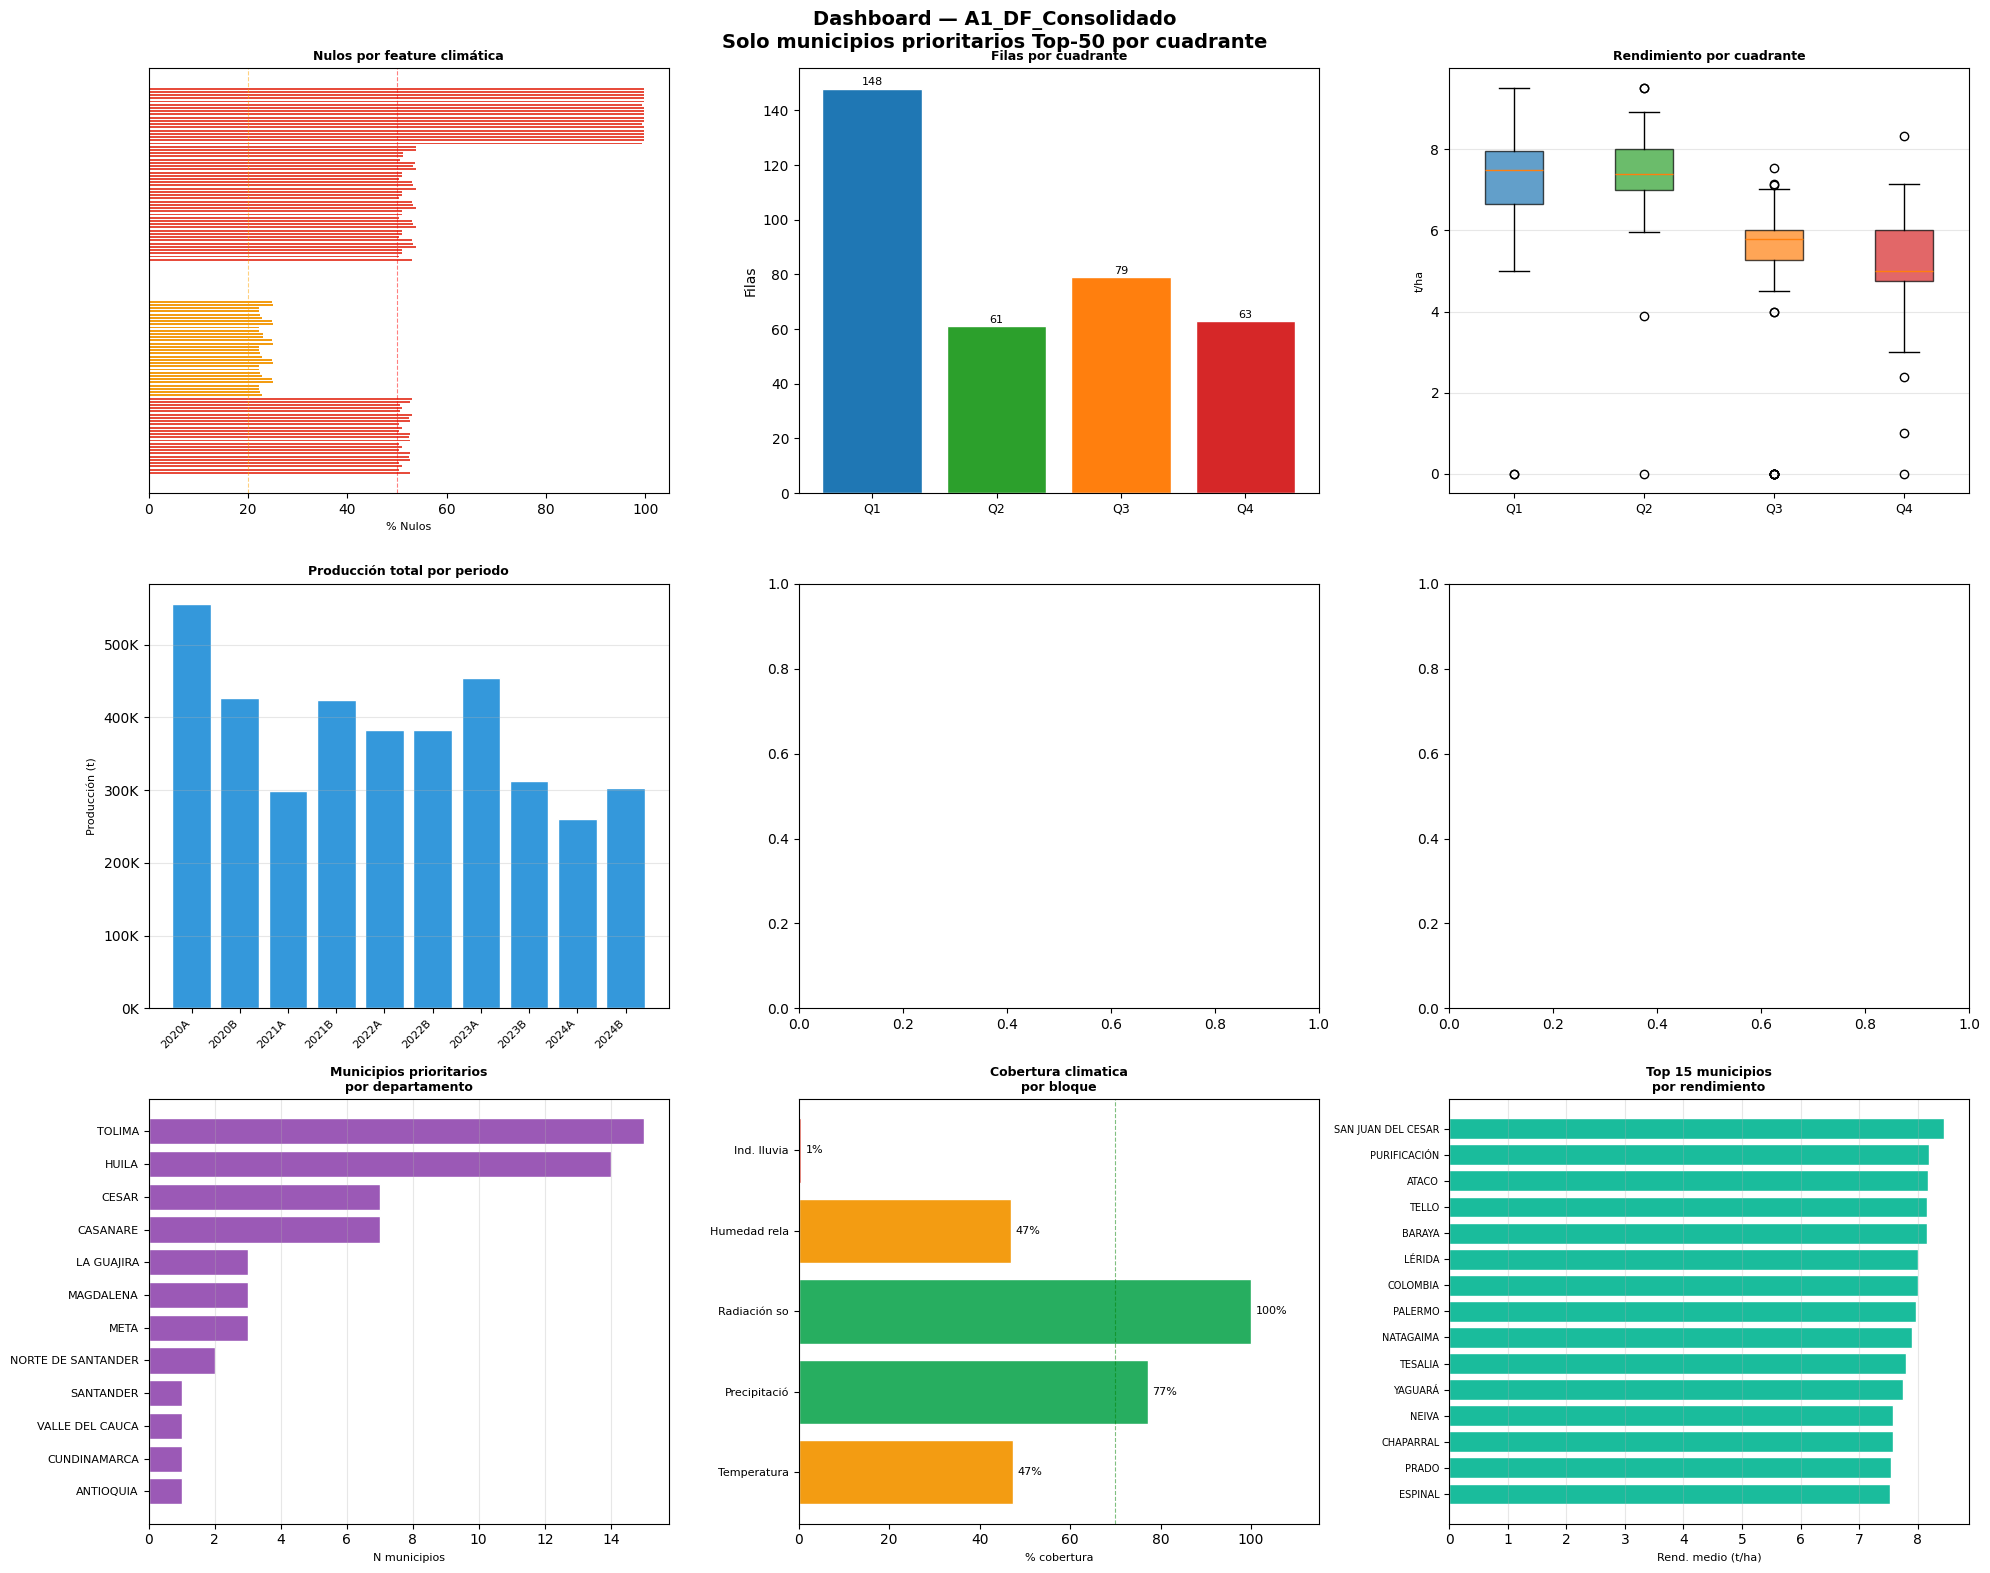

✅ Dashboard guardado: data/master/A1_Dashboard.png


In [12]:
# ============================================================
# DASHBOARD — 9 paneles
# ============================================================

fig = plt.figure(figsize=(20, 16))
fig.suptitle(
    'Dashboard — A1_DF_Consolidado\nSolo municipios prioritarios Top-50 por cuadrante',
    fontsize=14, fontweight='bold', y=0.98
)
colores_q = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']

cols_clima_all  = COLS_TEMP + COLS_PREC + COLS_RAD + COLS_HR + COLS_LLUVIA
cols_clima_pres = [c for c in cols_clima_all if c in df_maestro.columns]

# Panel 1: Mapa de nulos
ax1 = fig.add_subplot(3, 3, 1)
if cols_clima_pres:
    nulos_pct = df_maestro[cols_clima_pres].isna().mean() * 100
    ax1.barh(range(len(nulos_pct)), nulos_pct.values,
             color=['#e74c3c' if v > 50 else '#f39c12' if v > 20 else '#27ae60'
                    for v in nulos_pct.values], height=0.6)
    ax1.set_yticks([])
    ax1.set_xlabel('% Nulos', fontsize=8)
    ax1.set_title('Nulos por feature climática', fontsize=9, fontweight='bold')
    ax1.axvline(20, color='orange', ls='--', alpha=0.5, lw=0.8)
    ax1.axvline(50, color='red',    ls='--', alpha=0.5, lw=0.8)

# Panel 2: Filas por cuadrante
ax2 = fig.add_subplot(3, 3, 2)
if 'Cuadrante' in df_maestro.columns:
    conteo_q = df_maestro['Cuadrante'].value_counts().sort_index()
    bars = ax2.bar(range(len(conteo_q)), conteo_q.values,
                   color=colores_q[:len(conteo_q)], edgecolor='white')
    ax2.set_xticks(range(len(conteo_q)))
    ax2.set_xticklabels([q[:2] for q in conteo_q.index], fontsize=9)
    ax2.set_ylabel('Filas')
    ax2.set_title('Filas por cuadrante', fontsize=9, fontweight='bold')
    for bar, val in zip(bars, conteo_q.values):
        ax2.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5, str(val),
                 ha='center', va='bottom', fontsize=8)

# Panel 3: Boxplot rendimiento por cuadrante
ax3 = fig.add_subplot(3, 3, 3)
if 'Cuadrante' in df_maestro.columns and COL_RENDIMIENTO in df_maestro.columns:
    cuads = sorted(df_maestro['Cuadrante'].unique())
    datos_q = [df_maestro[df_maestro['Cuadrante'] == q][COL_RENDIMIENTO]
               .dropna().values for q in cuads]
    bp = ax3.boxplot(datos_q, patch_artist=True)
    for patch, color in zip(bp['boxes'], colores_q[:len(cuads)]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax3.set_xticklabels([q[:2] for q in cuads], fontsize=9)
    ax3.set_ylabel('t/ha', fontsize=8)
    ax3.set_title('Rendimiento por cuadrante', fontsize=9, fontweight='bold')
    ax3.grid(axis='y', alpha=0.3)

# Panel 4: Producción por periodo
ax4 = fig.add_subplot(3, 3, 4)
if COL_PRODUCCION in df_maestro.columns:
    pp = df_maestro.groupby('Periodo')[COL_PRODUCCION].sum().sort_index()
    ax4.bar(range(len(pp)), pp.values, color='#3498db', edgecolor='white')
    ax4.set_xticks(range(len(pp)))
    ax4.set_xticklabels(pp.index, rotation=45, ha='right', fontsize=8)
    ax4.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K')
    )
    ax4.set_ylabel('Producción (t)', fontsize=8)
    ax4.set_title('Producción total por periodo', fontsize=9, fontweight='bold')
    ax4.grid(axis='y', alpha=0.3)

# Panel 5: Scatter Temperatura m3 vs Rendimiento
ax5 = fig.add_subplot(3, 3, 5)
col_temp3 = 'temperatura_m3'
if col_temp3 in df_maestro.columns and COL_RENDIMIENTO in df_maestro.columns:
    sc = df_maestro[[col_temp3, COL_RENDIMIENTO]].dropna()
    ax5.scatter(sc[col_temp3], sc[COL_RENDIMIENTO], alpha=0.35, s=12, c='#e74c3c')
    ax5.set_xlabel('Temp. m3 (C)', fontsize=8)
    ax5.set_ylabel('Rendimiento (t/ha)', fontsize=8)
    ax5.set_title('Temp. m3 vs Rendimiento', fontsize=9, fontweight='bold')
    ax5.grid(alpha=0.25)

# Panel 6: Scatter Precipitación m3 vs Rendimiento
ax6 = fig.add_subplot(3, 3, 6)
col_prec3 = 'precipitacion_m3'
if col_prec3 in df_maestro.columns and COL_RENDIMIENTO in df_maestro.columns:
    sc = df_maestro[[col_prec3, COL_RENDIMIENTO]].dropna()
    ax6.scatter(sc[col_prec3], sc[COL_RENDIMIENTO], alpha=0.35, s=12, c='#27ae60')
    ax6.set_xlabel('Precip. m3 (mm)', fontsize=8)
    ax6.set_ylabel('Rendimiento (t/ha)', fontsize=8)
    ax6.set_title('Precip. m3 vs Rendimiento', fontsize=9, fontweight='bold')
    ax6.grid(alpha=0.25)

# Panel 7: Municipios por departamento
ax7 = fig.add_subplot(3, 3, 7)
munis_depto = (df_maestro.groupby('Departamento')['Municipio']
               .nunique().sort_values(ascending=True))
ax7.barh(range(len(munis_depto)), munis_depto.values,
         color='#9b59b6', edgecolor='white')
ax7.set_yticks(range(len(munis_depto)))
ax7.set_yticklabels(munis_depto.index, fontsize=8)
ax7.set_xlabel('N municipios', fontsize=8)
ax7.set_title('Municipios prioritarios\npor departamento', fontsize=9, fontweight='bold')
ax7.grid(axis='x', alpha=0.3)

# Panel 8: Cobertura climática por bloque
ax8 = fig.add_subplot(3, 3, 8)
coberturas, nombres_bl = [], []
for nb_str, cols_b in bloques_qc:
    cols_p = [c for c in cols_b if c in df_maestro.columns]
    if cols_p:
        pct = df_maestro[cols_p[0]].notna().mean() * 100
        coberturas.append(pct)
        nombres_bl.append(nb_str[:12])
if coberturas:
    colores_cob = ['#27ae60' if v >= 70 else '#f39c12' if v >= 40 else '#e74c3c'
                   for v in coberturas]
    ax8.barh(range(len(coberturas)), coberturas,
             color=colores_cob, edgecolor='white')
    ax8.set_yticks(range(len(nombres_bl)))
    ax8.set_yticklabels(nombres_bl, fontsize=8)
    ax8.set_xlim(0, 115)
    ax8.set_xlabel('% cobertura', fontsize=8)
    ax8.set_title('Cobertura climatica\npor bloque', fontsize=9, fontweight='bold')
    ax8.axvline(70, color='green', ls='--', alpha=0.5, lw=0.8)
    for i, v in enumerate(coberturas):
        ax8.text(v + 1, i, f'{v:.0f}%', va='center', fontsize=8)

# Panel 9: Top 15 municipios por rendimiento
ax9 = fig.add_subplot(3, 3, 9)
if COL_RENDIMIENTO in df_maestro.columns:
    rend_mun = (df_maestro.groupby('Municipio')[COL_RENDIMIENTO]
                .mean().sort_values(ascending=False).head(15))
    ax9.barh(range(len(rend_mun)), rend_mun.values[::-1],
             color='#1abc9c', edgecolor='white')
    ax9.set_yticks(range(len(rend_mun)))
    ax9.set_yticklabels(rend_mun.index[::-1], fontsize=7)
    ax9.set_xlabel('Rend. medio (t/ha)', fontsize=8)
    ax9.set_title('Top 15 municipios\npor rendimiento', fontsize=9, fontweight='bold')
    ax9.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'A1_Dashboard.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('✅ Dashboard guardado: data/master/A1_Dashboard.png')

---
## 💾 CELDA 13 — Guardar dataset maestro

Exporta `A1_DF_Consolidado.parquet` con compresión Snappy (sin límite de filas, formato óptimo para MOD-07) y `A1_DF_Consolidado.xlsx` (inspección visual, truncado a 1,048,576 filas si aplica). El archivo Parquet es el insumo obligatorio para MOD-07.

In [13]:
# ============================================================
# GUARDAR DATASET MAESTRO
# ============================================================

print('💾 Guardando A1_DF_Consolidado...')
print()
guardar_maestro(
    df_maestro,
    ruta_xlsx    = ARCHIVO_CONSOLIDADO,
    ruta_parquet = ARCHIVO_CONSOLIDADO_PARQUET
)

💾 Guardando A1_DF_Consolidado...

   OK Parquet -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master/A1_DF_Consolidado.parquet
      351 filas x 144 cols
   OK Excel  -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master/A1_DF_Consolidado.xlsx


---
## 📋 CELDA 14 — Resumen de ejecución del módulo

Reporta: archivos generados con tamaños, dimensiones del dataset consolidado (filas × columnas por bloque), municipios incluidos/excluidos con el criterio parcial, periodos cubiertos y porcentaje de nulos pendientes para imputación en MOD-07.

In [14]:
# ============================================================
# RESUMEN FINAL — MOD-06 completado
# ============================================================

sep = '=' * 65
print(sep)
print('  ✅ MOD-06 — Consolidación Dataset Maestro  COMPLETADO')
print('  Version 3.0 — Municipios con cobertura climatica minima (>=1 periodo)')
print(sep)

print()
print('📦 Archivos generados:')
salidas = [
    ('data/master/', 'A1_DF_Consolidado.parquet',
     f'{df_maestro.shape[0]:,} filas x {df_maestro.shape[1]} cols  <- usar en MOD-07'),
    ('data/master/', 'A1_DF_Consolidado.xlsx',
     'inspección visual'),
    ('data/master/', 'A1_Dashboard.png',
     'Dashboard 9 paneles'),
]
for carpeta, archivo, desc in salidas:
    print(f'   📄 {carpeta}{archivo}')
    print(f'      {desc}')

print()
print('📐 Estructura del Dataset Maestro:')
print(f'   {"Bloque":<30}  Cols')
print(f'   {"─"*38}')
for nombre_b, cols_b in [
    ('Identificadores (clave)',    COLS_ID_BASE),
    ('Metadatos EVA',              COLS_META),
    ('Variables objetivo',         COLS_TARGET),
    ('Temperatura (m1..m6)',       COLS_TEMP),
    ('Precipitacion (m1..m6)',     COLS_PREC),
    ('Radiacion solar (m1..m6)',   COLS_RAD),
    ('Humedad relativa (m1..m6)',  COLS_HR),
    ('Ind. lluvia (m1..m6)',       COLS_LLUVIA),
    ('Otras (EVA adicionales)',    COLS_OTRAS),
]:
    cols_p = [c for c in cols_b if c in df_maestro.columns]
    print(f'   {nombre_b:<30}  {len(cols_p):>3}')
print(f'   {"─"*38}')
print(f'   {"TOTAL":<30}  {df_maestro.shape[1]:>3}')

print()
print('🏘️  Municipios por cuadrante:')
if 'Cuadrante' in df_maestro.columns:
    for q, grp in df_maestro.groupby('Cuadrante'):
        munis = grp[['Departamento','Municipio']].drop_duplicates().shape[0]
        print(f'   {q}: {munis} municipios | {len(grp):,} filas')

print()
print('📅 Cobertura temporal:')
print(f'   Periodos: {sorted(df_maestro["Periodo"].unique())}')
print(f'   Departamentos: {df_maestro["Departamento"].nunique()}')
print(f'   Municipios   : {df_maestro["Municipio"].nunique()} '
      f'(de {len(pares_prioritarios)} prioritarios)')

print()
print('⚠️  Nulos por bloque (pendientes MOD-07):')
nulos_r = df_maestro.isna().mean().mul(100)
for nombre_b, cols_b in bloques_qc:
    cols_p = [c for c in cols_b if c in df_maestro.columns]
    if not cols_p:
        continue
    pct_med = nulos_r[cols_p].mean()
    emoji = '✅' if pct_med < 10 else ('⚠️ ' if pct_med < 40 else '❌')
    print(f'   {emoji} {nombre_b:<22}: {pct_med:.1f}% nulos promedio')

print()
print('➡️  Siguiente módulo : MOD-07 — Imputación y Control de Calidad')
print('    Entrada          : data/master/A1_DF_Consolidado.parquet')
print('    Estrategia       : KNN por departamento + mediana global de respaldo')
print(sep)

print()
print('🔎 Vista previa (5 filas):')
cols_preview = COLS_ID_BASE.copy()
if 'Cuadrante' in df_maestro.columns:
    cols_preview.append('Cuadrante')
cols_preview += COLS_TARGET[:2] + COLS_TEMP[:2] + COLS_PREC[:2]
cols_preview = [c for c in cols_preview if c in df_maestro.columns]
display(df_maestro[cols_preview].head(5))

  ✅ MOD-06 — Consolidación Dataset Maestro  COMPLETADO
  Version 3.0 — Municipios con cobertura climatica minima (>=1 periodo)

📦 Archivos generados:
   📄 data/master/A1_DF_Consolidado.parquet
      351 filas x 144 cols  <- usar en MOD-07
   📄 data/master/A1_DF_Consolidado.xlsx
      inspección visual
   📄 data/master/A1_Dashboard.png
      Dashboard 9 paneles

📐 Estructura del Dataset Maestro:
   Bloque                          Cols
   ──────────────────────────────────────
   Identificadores (clave)           3
   Metadatos EVA                     4
   Variables objetivo                4
   Temperatura (m1..m6)             24
   Precipitacion (m1..m6)           30
   Radiacion solar (m1..m6)         12
   Humedad relativa (m1..m6)        36
   Ind. lluvia (m1..m6)             18
   Otras (EVA adicionales)          13
   ──────────────────────────────────────
   TOTAL                           144

🏘️  Municipios por cuadrante:
   Q1 - Alto Rend + Alta Prod: 24 municipios | 148 filas


,Periodo,Departamento,Municipio,Cuadrante,Área sembrada (ha),Área cosechada (ha),temperatura_maxima_m1,temperatura_maxima_m2,precipitacion_maxima_m1,precipitacion_maxima_m2
0,2020A,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,110.0,110.0,NaN,NaN,0.0,0.0
1,2021A,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,110.0,110.0,NaN,NaN,0.0,0.0
2,2022A,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,100.0,100.0,NaN,NaN,0.0,0.0
3,2022B,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,110.0,110.0,NaN,24.4,NaN,NaN
4,2023A,ANTIOQUIA,PUERTO BERRÍO,Q4 - Bajo Rend + Baja Prod,50.0,50.0,NaN,NaN,NaN,NaN
